# 0b_conjunto_treino — dos CSVs do GEE ao conjunto de treino

Etapa B do projeto redesenhado (pasta `C:\cmap_ftl\terraclass`). Junta os CSVs exportados pelo `0a_aquisicao` (v2) e grava o conjunto de treino **no mesmo formato do `0_sample_design`** do projeto atual (`patches_9x9.npy` + `metadados_patches.csv`), para que as versões adaptadas do `1_baselines` e do `2_treino_cnn` mudem pouco.

| Seção | O que faz |
|---|---|
| 1. Leitura | Monta cada linha do CSV como um patch (bandas × 9 × 9), na orientação conferida no 0a, e o patch do rótulo (9 × 9) |
| 2. Conferências | Faixa de valores, rótulo central igual à classe, contagens por ano, classe e órbita-ponto |
| 3. Distância à borda | Calcula, pelo rótulo da vizinhança, a distância do pixel central à borda (1 = pixel de borda); filtro opcional |
| 4. Vizinhos próximos | Remove sobreposição entre órbitas-ponto diferentes (< 270 m) e quase cópias na mesma cena e ano (< 45 m) |
| 5. Escala fixa | Reflectância → z com média e desvio de cada banda calculados no conjunto inteiro (substitui a padronização por cena) |
| 6. Folds | Divisão agrupada por órbita-ponto, estratificada pelas classes, em `N_FOLDS` folds e `N_REPETICOES` repetições |
| 7. Gravação e figuras | Arquivos de saída, mapa dos folds e exemplos de patches |

Lê só `dados\patches_csv\` e `resultados\0a_aquisicao\`; grava só em `resultados\0b_conjunto_treino\<NOME_CONJUNTO>\`. O data augmentation continua no `2_treino_cnn`, sorteado a cada lote.

## Parâmetros

In [1]:
# ============================== PARÂMETROS ==============================
PASTA_PROJETO = r"C:\cmap_ftl\terraclass"
PASTA_CSV     = rf"{PASTA_PROJETO}\dados\patches_csv"              # CSVs da v2 (com rotulo_x_y)
PASTA_0A      = rf"{PASTA_PROJETO}\resultados\0a_aquisicao"        # orientacao_patch.json, zona_exclusao.geojson
NOME_CONJUNTO = "6bandas"                                          # um nome por variação (ex.: "3bandas")
PASTA_SAIDA   = rf"{PASTA_PROJETO}\resultados\0b_conjunto_treino\{NOME_CONJUNTO}"

BANDAS_USADAS = ["B1", "B2", "B3", "B4", "B5", "B7"]   # ["B2", "B4", "B5"] reproduz a escolha de Reis et al.
CLASSES = {1: "F", 2: "VS", 3: "PA", 4: "AG"}
MULT_SR, ADD_SR = 2.75e-05, -0.2                        # número digital -> reflectância de superfície
FAIXA_VALIDA_SR = (7273, 43636)

FILTRO_BORDA = 0            # 0 = mantém todos; 1 = remove pixel central de borda; 2 = exige 5x5 com uma classe (como a v1)
DISTANCIA_OUTRA_CENA_M = 270   # entre órbitas-ponto diferentes: patches de 9x9 não podem se sobrepor (vazamento entre folds)
DISTANCIA_MESMA_CENA_M = 45    # mesma órbita-ponto e ano: remove centros vizinhos imediatos (quase cópias); 0 mantém todos

N_FOLDS = 5
N_REPETICOES = 5
SEMENTE = 42

In [2]:
import os, re, json, glob, time
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

if not os.path.abspath(PASTA_SAIDA).lower().startswith(os.path.abspath(PASTA_PROJETO).lower() + os.sep):
    raise ValueError(f"PASTA_SAIDA precisa ficar dentro de {PASTA_PROJETO}")
os.makedirs(PASTA_SAIDA, exist_ok=True)

with open(os.path.join(PASTA_0A, "orientacao_patch.json"), encoding="utf-8") as arq:
    orientacao = json.load(arq)
if not orientacao["ok"]:
    raise ValueError("A conferência do 0a (orientação do patch) não passou.")
R = int(orientacao["raio"])
N = 2 * R + 1
CODIGOS = sorted(CLASSES)
print("Orientação do 0a:", orientacao["orientacao"], "| base dos índices:", orientacao["base"])
print("Bandas:", BANDAS_USADAS, "| saída:", PASTA_SAIDA)

Orientação do 0a: linha=+y, coluna=+x | base dos índices: -4
Bandas: ['B1', 'B2', 'B3', 'B4', 'B5', 'B7'] | saída: C:\cmap_ftl\terraclass\resultados\0b_conjunto_treino\6bandas


## 1. Leitura dos CSVs

O GEE grava as colunas em ordem alfabética, então o patch é montado **pelos nomes**: para cada posição [linha, coluna] do patch, calcula-se o deslocamento (x, y) correspondente com a orientação conferida no 0a e lê-se a coluna `SR_Bn_x_y`. Com a orientação encontrada (linha = 4 + y, coluna = 4 + x), o pixel [0, 0] do patch é a coluna `_-4_-4`, e a linha cresce para baixo, como nas imagens. O mesmo vale para o rótulo (`rotulo_x_y`).

Os valores ficam em números digitais (`uint16`) até a seção 5.

In [3]:
# nome da coluna (sufixo _x_y) de cada posição [linha, coluna] do patch, pela orientação do 0a
lx, ly = orientacao["linha"]["x"], orientacao["linha"]["y"]
cx, cy = orientacao["coluna"]["x"], orientacao["coluna"]["y"]
soma_base = R if orientacao["base"] == 0 else 0
sufixo = np.empty((N, N), dtype=object)
for lin in range(N):
    for col in range(N):
        a, b = lin - R, col - R
        dx, dy = lx * a + cx * b, ly * a + cy * b      # a matriz de orientação é ortogonal: inversa = transposta
        sufixo[lin, col] = f"_{dx + soma_base}_{dy + soma_base}"
COLS_IMAGEM = [f"SR_{banda}{s}" for banda in BANDAS_USADAS for s in sufixo.ravel()]
COLS_ROTULO = [f"rotulo{s}" for s in sufixo.ravel()]

arquivos = sorted(glob.glob(os.path.join(PASTA_CSV, "patches_*.csv")))
if not arquivos:
    raise FileNotFoundError(f"Nenhum patches_*.csv em {PASTA_CSV}")
partes_X, partes_rot, partes_meta, vazios = [], [], [], []
inicio = time.time()
for arq in arquivos:
    try:
        df = pd.read_csv(arq)
    except pd.errors.EmptyDataError:
        vazios.append(os.path.basename(arq))
        continue
    if len(df) == 0:
        vazios.append(os.path.basename(arq))
        continue
    faltam = [c for c in COLS_IMAGEM + COLS_ROTULO if c not in df.columns]
    if faltam:
        raise ValueError(f"{os.path.basename(arq)}: faltam {len(faltam)} colunas (ex.: {faltam[:3]}). "
                         "Se faltam as rotulo_x_y, o arquivo é da exportação v1.")
    partes_X.append(df[COLS_IMAGEM].to_numpy(dtype=np.uint16).reshape(len(df), len(BANDAS_USADAS), N, N))
    partes_rot.append(df[COLS_ROTULO].to_numpy(dtype=np.uint8).reshape(len(df), N, N))
    coords = np.array([json.loads(g)["coordinates"] for g in df[".geo"]])
    partes_meta.append(pd.DataFrame({"ano": df["ano"].astype(int), "classe": df["classe"].astype(int),
                                     "local": df["orbita_ponto"].astype(int), "data": df["data"].astype(int),
                                     "lon": coords[:, 0], "lat": coords[:, 1],
                                     "arquivo": os.path.basename(arq)[:-4]}))

X_nd = np.concatenate(partes_X)
rotulos = np.concatenate(partes_rot)
meta = pd.concat(partes_meta, ignore_index=True)
del partes_X, partes_rot, partes_meta
meta["orbita_ponto"] = [f"{v // 1000:03d}/{v % 1000:03d}" for v in meta["local"]]
meta["classe_sigla"] = meta["classe"].map(CLASSES)
print(f"{len(arquivos)} arquivos ({len(vazios)} vazios) | {len(meta)} patches | X {X_nd.shape} | "
      f"rótulos {rotulos.shape} | {time.time() - inicio:.0f} s")

113 arquivos (0 vazios) | 107460 patches | X (107460, 6, 9, 9) | rótulos (107460, 9, 9) | 9 s


## 2. Conferências

- todos os números digitais dentro da faixa válida (o 0a só sorteou patches limpos);
- o rótulo do pixel central (`rotulo_0_0`) igual à coluna `classe`;
- só as classes da legenda;
- contagens por ano, classe e órbita-ponto.

In [4]:
fora_faixa = int(((X_nd < FAIXA_VALIDA_SR[0]) | (X_nd > FAIXA_VALIDA_SR[1])).any(axis=(1, 2, 3)).sum())
centro_difere = int((rotulos[:, R, R] != meta["classe"].to_numpy()).sum())
fora_legenda = sorted(set(meta["classe"]) - set(CODIGOS))
print(f"Patches com valor fora da faixa válida: {fora_faixa}")
print(f"Patches com rótulo central diferente da classe: {centro_difere}")
print(f"Classes fora da legenda: {fora_legenda if fora_legenda else 'nenhuma'}")
if fora_faixa or centro_difere or fora_legenda:
    raise ValueError("Conferência falhou: veja as contagens acima.")

tab = meta.pivot_table(index="ano", columns="classe_sigla", values="classe", aggfunc="size", fill_value=0)
tab = tab[[s for s in CLASSES.values() if s in tab.columns]]
tab["total"] = tab.sum(axis=1)
tab.loc["total"] = tab.sum()
print("\nPatches lidos por ano e classe:\n", tab.to_string())
por_local = meta.groupby("orbita_ponto")["classe_sigla"].value_counts().unstack(fill_value=0)
print(f"\nÓrbitas-ponto: {len(por_local)} | com AG: {int((por_local.get('AG', 0) > 0).sum())}")

Patches com valor fora da faixa válida: 0
Patches com rótulo central diferente da classe: 0
Classes fora da legenda: nenhuma

Patches lidos por ano e classe:
 classe_sigla      F     VS     PA    AG   total
ano                                            
2008          18900  18900  18129  3519   59448
2010          15000  14700  14700  3612   48012
total         33900  33600  32829  7131  107460

Órbitas-ponto: 63 | com AG: 16


## 3. Distância à borda

Com o rótulo da vizinhança, calcula-se a distância (em pixels, métrica de tabuleiro) do pixel central até o pixel mais próximo da janela com outro rótulo: 1 = pixel de borda (outra classe na janela 3 × 3), 2 = borda na 5 × 5, até 4; **5 = nenhum outro rótulo na janela 9 × 9**. "Outro rótulo" inclui outra classe, classe fora da legenda (9) e área sem dado (0). A coluna `dist_borda_px` tem o mesmo significado da do `0_sample_design`.

`FILTRO_BORDA` permite testar a exclusão de pixels de borda sem nova exportação: 0 mantém todos (padrão do desenho), 1 remove os pixels de borda e 2 reproduz a regra de interior da v1.

In [5]:
centro = rotulos[:, R, R][:, None, None]
dist = np.full(len(meta), R + 1, dtype=np.int8)
for d in range(R, 0, -1):                       # do maior para o menor: fica a menor distância com outro rótulo
    janela = rotulos[:, R - d:R + d + 1, R - d:R + d + 1]
    dist[(janela != centro).any(axis=(1, 2))] = d
meta["dist_borda_px"] = dist

tabela_borda = pd.DataFrame({
    "classe": meta["classe_sigla"],
    "borda 3x3 (%)": (dist == 1) * 100.0,
    "borda 5x5 (%)": (dist <= 2) * 100.0,
    "borda 9x9 (%)": (dist <= R) * 100.0,
}).groupby("classe").mean().reindex(list(CLASSES.values()))
tabela_borda.loc["todas"] = [(dist == 1).mean() * 100, (dist <= 2).mean() * 100, (dist <= R).mean() * 100]
tabela_borda = tabela_borda.round(1)
tabela_borda.to_csv(os.path.join(PASTA_SAIDA, "patches_com_borda.csv"))
print("Patches com outro rótulo na janela (a 5x5 é a entrada da CNN):\n", tabela_borda.to_string())

if FILTRO_BORDA > 0:
    manter = dist > FILTRO_BORDA
    print(f"\nFILTRO_BORDA = {FILTRO_BORDA}: removidos {int((~manter).sum())} patches")
    X_nd, rotulos, meta = X_nd[manter], rotulos[manter], meta[manter].reset_index(drop=True)

Patches com outro rótulo na janela (a 5x5 é a entrada da CNN):
         borda 3x3 (%)  borda 5x5 (%)  borda 9x9 (%)
classe                                             
F                 4.1            7.6           13.5
VS               46.0           68.2           85.8
PA               28.7           44.7           63.7
AG               24.4           39.2           57.4
todas            26.1           40.0           54.4


## 4. Vizinhos próximos

Há duas situações diferentes:

- **Órbitas-ponto diferentes, em qualquer ano** (limite `DISTANCIA_OUTRA_CENA_M` = 270 m = 9 pixels): cenas vizinhas se sobrepõem, e o mesmo lugar poderia cair em folds diferentes. Isso é vazamento entre treino e validação, então os patches de 9 × 9 não podem se sobrepor.
- **Mesma órbita-ponto e mesmo ano** (limite `DISTANCIA_MESMA_CENA_M` = 45 m): aqui não há vazamento, porque os dois patches ficam no mesmo fold. Remove-se só o caso de centros vizinhos imediatos (inclusive na diagonal), cujos recortes 5 × 5 compartilham 80% dos pixels. Um limite maior descartaria boa parte da Agricultura: nas poucas cenas com AG, os 300 pontos por classe caem em áreas pequenas, e o vizinho mais próximo fica, na mediana, a 90 m (na primeira execução, com 270 m também dentro da cena, a AG caiu de 7.131 para 2.961 patches).

O mesmo lugar na mesma órbita-ponto em 2008 e em 2010 é sempre mantido: são datas diferentes e ficam no mesmo fold. Os conflitos são resolvidos percorrendo os patches em ordem aleatória (semente fixa) e mantendo um patch só se nenhum vizinho em conflito já foi mantido. As distâncias são calculadas em 3D sobre a esfera (raio de 6.371 km).

In [6]:
lat_r, lon_r = np.radians(meta["lat"].to_numpy()), np.radians(meta["lon"].to_numpy())
xyz = 6371008.8 * np.column_stack([np.cos(lat_r) * np.cos(lon_r), np.cos(lat_r) * np.sin(lon_r), np.sin(lat_r)])
pares = cKDTree(xyz).query_pairs(r=max(DISTANCIA_OUTRA_CENA_M, DISTANCIA_MESMA_CENA_M), output_type="ndarray")
local_arr, ano_arr = meta["local"].to_numpy(), meta["ano"].to_numpy()
if len(pares):
    distancia = np.linalg.norm(xyz[pares[:, 0]] - xyz[pares[:, 1]], axis=1)
    outra_orbita = (local_arr[pares[:, 0]] != local_arr[pares[:, 1]]) & (distancia < DISTANCIA_OUTRA_CENA_M)
    mesma_cena_ano = ((local_arr[pares[:, 0]] == local_arr[pares[:, 1]]) & (ano_arr[pares[:, 0]] == ano_arr[pares[:, 1]])
                      & (distancia < DISTANCIA_MESMA_CENA_M))
    conflitos = pares[outra_orbita | mesma_cena_ano]
else:
    outra_orbita = mesma_cena_ano = np.zeros(0, dtype=bool)
    conflitos = pares
print(f"Pares em conflito: {len(conflitos)} (outra órbita-ponto a menos de {DISTANCIA_OUTRA_CENA_M} m: {int(outra_orbita.sum())}; "
      f"mesma cena e ano a menos de {DISTANCIA_MESMA_CENA_M} m: {int(mesma_cena_ano.sum())})")

vizinhos = {}
for i, j in conflitos:
    vizinhos.setdefault(int(i), []).append(int(j))
    vizinhos.setdefault(int(j), []).append(int(i))
mantido = np.zeros(len(meta), dtype=bool)
for i in np.random.default_rng(SEMENTE).permutation(len(meta)):
    if not any(mantido[j] for j in vizinhos.get(int(i), [])):
        mantido[i] = True
removidos = meta.loc[~mantido, ["arquivo", "classe_sigla", "lon", "lat"]]
removidos.to_csv(os.path.join(PASTA_SAIDA, "patches_removidos_vizinhos.csv"), index=False)
print(f"Removidos: {len(removidos)} | por classe: {removidos['classe_sigla'].value_counts().to_dict()}")
X_nd, rotulos, meta = X_nd[mantido], rotulos[mantido], meta[mantido].reset_index(drop=True)
meta.insert(0, "id", np.arange(len(meta)))
print(f"Patches no conjunto final: {len(meta)}")

Pares em conflito: 22150 (outra órbita-ponto a menos de 270 m: 13848; mesma cena e ano a menos de 45 m: 8302)
Removidos: 6817 | por classe: {'PA': 2647, 'VS': 2043, 'AG': 2000, 'F': 127}
Patches no conjunto final: 100643


## 5. Escala radiométrica fixa

No projeto atual, cada banda era padronizada pela média e pelo desvio **da própria cena**. Com cenas de todo o Pará, isso deixaria o mesmo alvo com valores diferentes em cada cena (uma cena quase toda de floresta tem média muito diferente de uma cena agrícola). Aqui, a reflectância de superfície (ρ = ND × 2,75 × 10⁻⁵ − 0,2) de cada banda é padronizada com **uma única média e um único desvio**, calculados em todos os pixels de todos os patches do conjunto final. As mesmas estatísticas, gravadas em `escala_fixa.json`, serão aplicadas às seis imagens da área de estudo na inferência.

As estatísticas não usam rótulos, e a área de estudo não participa delas. Como incluem os patches de todos os folds, há uma pequena troca de informação entre treino e validação dos folds, desprezível diante de mais de 100 mil patches.

Para o MaxVer com covariância completa e para o RF, uma transformação linear comum a todas as amostras não muda o resultado; para a CNN, a escala importa.

In [7]:
X = np.empty(X_nd.shape, dtype=np.float32)
estatisticas = {}
for b, banda in enumerate(BANDAS_USADAS):
    refl = X_nd[:, b].astype(np.float32) * MULT_SR + ADD_SR
    media, desvio = float(refl.mean(dtype=np.float64)), float(refl.std(dtype=np.float64))
    estatisticas[banda] = {"media": media, "desvio": desvio,
                           "p01": float(np.percentile(refl, 1)), "p99": float(np.percentile(refl, 99))}
    X[:, b] = (refl - media) / desvio
del X_nd
with open(os.path.join(PASTA_SAIDA, "escala_fixa.json"), "w", encoding="utf-8") as arq:
    json.dump({"bandas": BANDAS_USADAS, "mult": MULT_SR, "add": ADD_SR,
               "uso": "z = (rho - media) / desvio, com rho = ND * mult + add",
               "calculada_em": f"{len(meta)} patches x {N * N} pixels (conjunto final do 0b)",
               "estatisticas": estatisticas}, arq, indent=2, ensure_ascii=False)
tab_escala = pd.DataFrame(estatisticas).T.round(4)
print(tab_escala.to_string())

media_classe = pd.DataFrame(X[:, :, R, R], columns=BANDAS_USADAS).groupby(meta["classe_sigla"].to_numpy()).mean()
print("\nMédia do pixel central por classe (unidades z):\n", media_classe.reindex(list(CLASSES.values())).round(2).to_string())

     media  desvio     p01     p99
B1  0.0262  0.0136  0.0088  0.0787
B2  0.0501  0.0202  0.0247  0.1264
B3  0.0426  0.0277  0.0161  0.1568
B4  0.2926  0.0526  0.1651  0.4306
B5  0.1677  0.0570  0.0788  0.3599
B7  0.0720  0.0405  0.0269  0.2247

Média do pixel central por classe (unidades z):
       B1    B2    B3    B4    B5    B7
F  -0.48 -0.60 -0.56 -0.30 -0.66 -0.59
VS -0.22 -0.22 -0.27  0.26 -0.20 -0.26
PA  0.42  0.55  0.50  0.17  0.63  0.57
AG  1.99  2.06  2.34 -0.21  2.03  2.20


## 6. Divisão agrupada por órbita-ponto

O grupo espacial (coluna `local`) passa a ser a **órbita-ponto**: todos os patches de uma cena, em 2008 e em 2010, ficam no mesmo fold. A distribuição repete a regra do `0_sample_design`: começa pelos grupos da classe mais rara (AG, presente em poucas órbitas-ponto) e põe cada grupo no fold com menos grupos dessa classe (desempate: menos patches), para que toda classe apareça em todos os folds sempre que possível.

As colunas `fold_r0` … `fold_r{N_REPETICOES-1}` trazem o fold de cada patch em cada repetição. A forma de usar os folds (por exemplo, teste = fold f e validação = fold f + 1, como antes) fica para os notebooks de treino. A avaliação principal do projeto continua sendo a área de estudo, que não está em nenhum fold.

In [8]:
tem_classe = pd.crosstab(meta["local"], meta["classe"]).reindex(columns=CODIGOS, fill_value=0) > 0
px_local = meta.groupby("local").size()
locais_ids = tem_classe.index.to_numpy()
n_locais_classe = tem_classe.sum(axis=0)
print("Órbitas-ponto por classe:", {CLASSES[c]: int(n) for c, n in n_locais_classe.items()})

posto = {c: p for p, c in enumerate(n_locais_classe.sort_values(kind="stable").index)}
matriz = tem_classe.to_numpy()
posto_local = np.array([min(posto[CODIGOS[j]] for j in np.nonzero(matriz[i])[0]) for i in range(len(locais_ids))])

for r in range(N_REPETICOES):
    rng = np.random.default_rng(SEMENTE + r)
    ordem = np.lexsort((rng.random(len(locais_ids)), posto_local))     # classe mais rara primeiro, empates ao acaso
    cont_classe = np.zeros((N_FOLDS, len(CODIGOS)), dtype=int)
    cont_px = np.zeros(N_FOLDS, dtype=int)
    fold_do_local = {}
    for i in ordem:
        j_rara = [j for j in np.nonzero(matriz[i])[0] if posto[CODIGOS[j]] == posto_local[i]][0]
        f = np.lexsort((rng.random(N_FOLDS), cont_px, cont_classe[:, j_rara]))[0]
        fold_do_local[locais_ids[i]] = f
        cont_classe[f] += matriz[i]
        cont_px[f] += px_local.loc[locais_ids[i]]
    meta[f"fold_r{r}"] = meta["local"].map(fold_do_local).astype(int)

# conferência: toda classe em treino, validação (f + 1) e teste (f) de cada divisão
problemas = []
for r in range(N_REPETICOES):
    for f in range(N_FOLDS):
        fv = (f + 1) % N_FOLDS
        conjuntos = {"teste": meta[f"fold_r{r}"] == f, "validacao": meta[f"fold_r{r}"] == fv}
        conjuntos["treino"] = ~(conjuntos["teste"] | conjuntos["validacao"])
        for nome, m in conjuntos.items():
            faltam = sorted(set(CODIGOS) - set(meta.loc[m, "classe"]))
            if faltam:
                problemas.append({"repeticao": r, "fold_teste": f, "conjunto": nome,
                                  "classes_ausentes": ", ".join(CLASSES[c] for c in faltam)})
tab_problemas = pd.DataFrame(problemas, columns=["repeticao", "fold_teste", "conjunto", "classes_ausentes"])
tab_problemas.to_csv(os.path.join(PASTA_SAIDA, "divisoes_com_classe_ausente.csv"), index=False)
print(f"Conjuntos com classe ausente: {len(tab_problemas)} de {N_REPETICOES * N_FOLDS * 3}")

resumo = meta.groupby(["fold_r0", "classe_sigla"]).agg(patches=("id", "size"), orbitas_ponto=("local", "nunique")).reset_index()
resumo.to_csv(os.path.join(PASTA_SAIDA, "resumo_folds_r0.csv"), index=False)
print("\nRepetição 0 — patches por fold e classe:")
print(resumo.pivot(index="classe_sigla", columns="fold_r0", values="patches").reindex(list(CLASSES.values())).fillna(0).astype(int).to_string())
print("\nRepetição 0 — órbitas-ponto por fold e classe:")
print(resumo.pivot(index="classe_sigla", columns="fold_r0", values="orbitas_ponto").reindex(list(CLASSES.values())).fillna(0).astype(int).to_string())

Órbitas-ponto por classe: {'F': 63, 'VS': 63, 'PA': 63, 'AG': 16}
Conjuntos com classe ausente: 0 de 75

Repetição 0 — patches por fold e classe:
fold_r0          0     1     2     3     4
classe_sigla                              
F             6863  6873  6580  6879  6578
VS            6527  6548  5820  6649  6013
PA            6271  6518  5077  6545  5771
AG            1400   549   794  1079  1309

Repetição 0 — órbitas-ponto por fold e classe:
fold_r0        0   1   2   3   4
classe_sigla                    
F             12  12  13  13  13
VS            12  12  13  13  13
PA            12  12  13  13  13
AG             3   3   3   4   3


## 7. Gravação e figuras

Conjunto final por ano e classe:
 classe_sigla      F     VS     PA    AG   total
ano                                            
2008          18828  17489  16132  2459   54908
2010          14945  14068  14050  2672   45735
total         33773  31557  30182  5131  100643


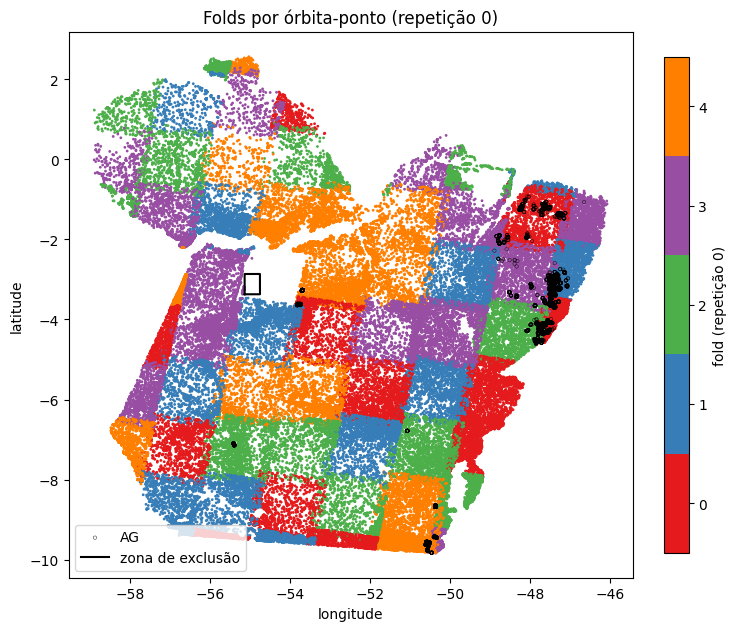

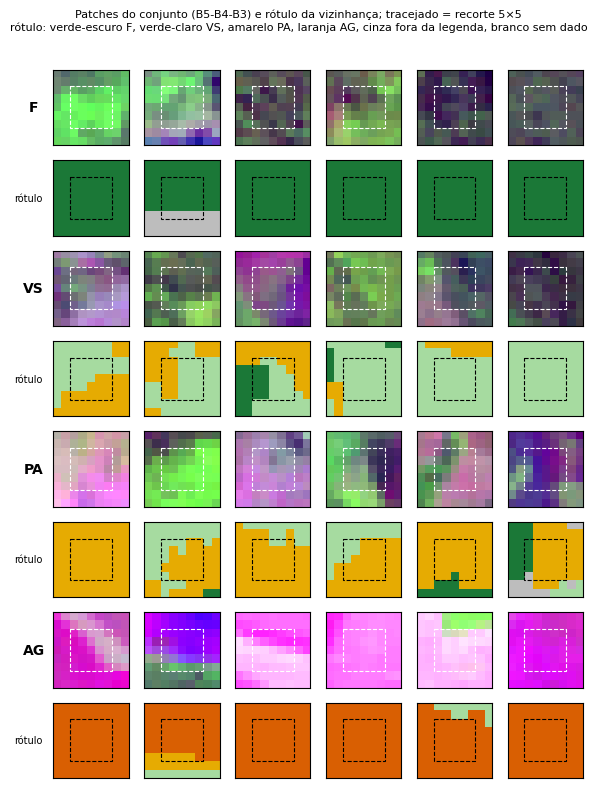

In [9]:
np.save(os.path.join(PASTA_SAIDA, f"patches_{N}x{N}.npy"), X)
np.save(os.path.join(PASTA_SAIDA, f"rotulos_{N}x{N}.npy"), rotulos)
colunas = ["id", "ano", "classe", "classe_sigla", "local", "orbita_ponto", "data", "lon", "lat", "dist_borda_px", "arquivo"] + \
          [f"fold_r{r}" for r in range(N_REPETICOES)]
meta[colunas].to_csv(os.path.join(PASTA_SAIDA, "metadados_patches.csv"), index=False)
with open(os.path.join(PASTA_SAIDA, "legenda.json"), "w", encoding="utf-8") as arq:
    json.dump({"classes": {str(k): v for k, v in CLASSES.items()}, "fora_da_legenda": 9, "sem_dado": 0,
               "bandas": BANDAS_USADAS, "filtro_borda": FILTRO_BORDA}, arq, indent=2, ensure_ascii=False)
final = meta.pivot_table(index="ano", columns="classe_sigla", values="id", aggfunc="size", fill_value=0)
final = final[[s for s in CLASSES.values() if s in final.columns]]
final["total"] = final.sum(axis=1)
final.loc["total"] = final.sum()
final.to_csv(os.path.join(PASTA_SAIDA, "resumo_conjunto.csv"))
print("Conjunto final por ano e classe:\n", final.to_string())

# mapa dos folds (repetição 0)
with open(os.path.join(PASTA_0A, "zona_exclusao.geojson"), encoding="utf-8") as arq:
    anel_zona = np.array(json.load(arq)["features"][0]["geometry"]["coordinates"][0])
cores = ListedColormap(["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628", "#f781bf"][:N_FOLDS])
fig, ax = plt.subplots(figsize=(8, 7.5))
sc = ax.scatter(meta["lon"], meta["lat"], c=meta["fold_r0"], cmap=cores, vmin=-0.5, vmax=N_FOLDS - 0.5, s=1)
ag = meta["classe_sigla"] == "AG"
ax.scatter(meta.loc[ag, "lon"], meta.loc[ag, "lat"], facecolors="none", edgecolors="k", s=6, lw=0.3, label="AG")
ax.plot(anel_zona[:, 0], anel_zona[:, 1], "k-", lw=1.5, label="zona de exclusão")
cb = fig.colorbar(sc, ax=ax, ticks=range(N_FOLDS), fraction=0.04); cb.set_label("fold (repetição 0)")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_aspect("equal"); ax.legend(loc="lower left")
ax.set_title("Folds por órbita-ponto (repetição 0)")
fig.savefig(os.path.join(PASTA_SAIDA, "mapa_folds_r0.png"), dpi=150, bbox_inches="tight")
plt.show()

# exemplos: patch (B5-B4-B3) e rótulo da vizinhança, por classe
iR, iG, iB = [BANDAS_USADAS.index(b) if b in BANDAS_USADAS else None for b in ("B5", "B4", "B3")]
if None not in (iR, iG, iB):
    rgb = np.stack([X[:, iR], X[:, iG], X[:, iB]], axis=-1)
    rgb = np.clip((rgb + 2.0) / 4.0, 0, 1)
    cores_rot = ListedColormap(["#ffffff", "#1b7837", "#a6dba0", "#e6ab02", "#d95f02", "#bdbdbd"])
    rot_plot = np.where(rotulos == 9, 5, np.minimum(rotulos, 5))
    rng = np.random.default_rng(SEMENTE)
    n_ex = 6
    fig, eixos = plt.subplots(2 * len(CODIGOS), n_ex, figsize=(n_ex * 1.0, 2 * len(CODIGOS) * 1.0))
    for i, cod in enumerate(CODIGOS):
        da_classe = np.where(meta["classe"].to_numpy() == cod)[0]
        idx = rng.choice(da_classe, min(n_ex, len(da_classe)), replace=False)
        for j, k in enumerate(idx):
            for linha, imagem, opc in ((2 * i, rgb[k], {}), (2 * i + 1, rot_plot[k], {"cmap": cores_rot, "vmin": 0, "vmax": 5})):
                a = eixos[linha, j]
                a.imshow(imagem, interpolation="nearest", **opc)
                a.add_patch(plt.Rectangle((R - 2.5, R - 2.5), 5, 5, fill=False, edgecolor="white" if linha % 2 == 0 else "black", lw=0.8, ls="--"))
                a.set_xticks([]); a.set_yticks([])
        eixos[2 * i, 0].set_ylabel(CLASSES[cod], rotation=0, labelpad=14, fontweight="bold", va="center")
        eixos[2 * i + 1, 0].set_ylabel("rótulo", rotation=0, labelpad=18, fontsize=7, va="center")
    fig.suptitle("Patches do conjunto (B5-B4-B3) e rótulo da vizinhança; tracejado = recorte 5×5\n"
                 "rótulo: verde-escuro F, verde-claro VS, amarelo PA, laranja AG, cinza fora da legenda, branco sem dado", fontsize=8)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(os.path.join(PASTA_SAIDA, "exemplos_patches.png"), dpi=200, bbox_inches="tight")
    plt.show()

## Saídas

| Arquivo | Conteúdo |
|---|---|
| `patches_9x9.npy` | patches na escala fixa (z), forma (n, bandas, 9, 9), na ordem de `BANDAS_USADAS`; mesmo formato do `0_sample_design` |
| `rotulos_9x9.npy` | rótulo do TerraClass em cada pixel do patch (1–4; 9 = fora da legenda; 0 = sem dado) |
| `metadados_patches.csv` | id, ano, classe, classe_sigla, local (órbita-ponto como número), orbita_ponto, data da cena, lon, lat, dist_borda_px, arquivo de origem, fold_r0… |
| `escala_fixa.json` | média e desvio de cada banda (usar na inferência das seis imagens) |
| `legenda.json` | classes, bandas e filtro de borda usados |
| `resumo_conjunto.csv`, `resumo_folds_r0.csv`, `patches_com_borda.csv`, `divisoes_com_classe_ausente.csv`, `patches_removidos_vizinhos.csv` | tabelas de conferência |
| `mapa_folds_r0.png`, `exemplos_patches.png` | figuras |

Para o recorte 5 × 5 usado pela CNN: `X[:, :, 2:7, 2:7]`.

In [10]:
for nome in sorted(os.listdir(PASTA_SAIDA)):
    print(f"{nome:40s} {os.path.getsize(os.path.join(PASTA_SAIDA, nome)) / 1e6:8.1f} MB")

divisoes_com_classe_ausente.csv               0.0 MB
escala_fixa.json                              0.0 MB
exemplos_patches.png                          0.1 MB
legenda.json                                  0.0 MB
mapa_folds_r0.png                             0.6 MB
metadados_patches.csv                        11.2 MB
patches_9x9.npy                             195.7 MB
patches_com_borda.csv                         0.0 MB
patches_removidos_vizinhos.csv                0.4 MB
resumo_conjunto.csv                           0.0 MB
resumo_folds_r0.csv                           0.0 MB
rotulos_9x9.npy                               8.2 MB
